# Your First AI Agent: The Agent Harness

In Session 2 you built a **Personal Wellness Assistant** by hand. You loaded a document, chunked it, embedded it, retrieved the closest chunks, and pasted them into a prompt. That pipeline always did the *same thing in the same order*:

```text
question -> retrieve -> answer
```

This session the model gets the steering wheel. Instead of hard-wiring the retrieve step, you hand the model a toolbox and let it *decide* what to do:

```text
question -> agent decides -> optional tool call(s) -> answer
```

That decision loop is the **agent harness**: a model wrapped in tools, instructions, a budget, and a trace you can read. We build one with LangChain 1.0's `create_agent`, turn the wellness guide into a tool the agent can call when it wants to (that's Agentic RAG), then wrap the loop in middleware so we can watch it and stop it running away.

### 🏗️ Build · 🚢 Ship · 🚀 Share
- **Build:** a baseline agent with `create_agent`, then an Agentic RAG agent that searches the guide on demand, wrapped in logging and a call limit.
- **Ship:** add your own tool or middleware and compare its trace to the baseline.
- **Share:** record a short walkthrough and post three lessons learned.

> NOTE: Built and tested with Python 3.11+. This folder is a self-contained `uv` project.

<a id="toy-project"></a>
## 🧘 The toy project: a Pocket Wellness Coach

Everything in this notebook builds one small thing: a **Pocket Wellness Coach** for a member we'll call Sam. Over a single day Sam asks very different kinds of questions, and Session 2's fixed *retrieve-then-answer* pipeline would treat them all the same. An agent routes each one to the right place:

| Sam asks… | The coach should… | Which tool |
| --- | --- | --- |
| "What stretches help my lower-back pain?" | look it up in the wellness guide | `search_wellness_knowledge` (RAG) |
| "How much water should I drink at 80 kg?" | do the math, not search the guide | `hydration_calculator` |
| "It's late. Got a wind-down routine?" | check the time, then find sleep tips | `get_current_time` + RAG |
| "Who won the 2022 World Cup?" | just answer; it's out of its lane | *(no tool)* |

The session is about teaching the coach to decide which row it's in, and letting you see and trust that decision. We build it with `create_agent`, back it with the wellness guide (Agentic RAG), and wrap it in middleware so a confused coach can't loop forever.

> The guide it reads is the course's `HealthWellnessGuide.txt`, with real chapters on exercise, hydration, sleep, and stress. The `hydration_calculator` comes straight from its Chapter 6 ("8 glasses / 64 oz, scaled to body size and activity").

## 🎯 By the End of This Session

You'll turn a fixed RAG pipeline into an agent that decides when to retrieve, and you'll understand every moving part. You'll be able to:

- **Explain the agent loop.** Describe how a model decides, step by step, whether to call a tool or answer, and how that differs from a fixed chain.
- **Define tools the model can call.** Write Python functions with the `@tool` decorator, and explain why the docstring and signature are the model's only instructions for a tool.
- **Build an agent with `create_agent`.** Assemble a model, tools, and a system prompt into a running harness in a few lines.
- **Inspect the loop, not just the answer.** Stream intermediate steps, pull out a reasoning trace, and render the compiled graph, so you can judge behavior instead of output.
- **Build Agentic RAG.** Chunk the wellness guide into a Qdrant store and wrap the retriever as a tool the agent calls only when it needs to.
- **Add middleware.** Log each turn with `before_model`/`after_model`, and set a model-call budget so the agent can't loop forever.
- **Reason about production.** Map each toy piece (on-disk Qdrant, three local tools, print-logging) to what a real deployment would harden.

## 📜 Table of Contents

- [🧘 The toy project: Pocket Wellness Coach](#toy-project)
- [🏃 How to Run This Notebook](#how-to-run)
- [🧑‍💻 Setup](#setup)
- [🏗️ By the End of the Sesh (the finished agent, first)](#by-the-end)

**🤜 Breakout Room #1**
- [✅ Task 1: From Pipeline to Agent Loop](#task-1)
- [✅ Task 2: The harness with no framework](#task-2)
- [✅ Task 3: Define Tools with `@tool`](#task-3)
- [✅ Task 4: Build the Baseline Agent with `create_agent`](#task-4)

**🤜 Breakout Room #2**
- [✅ Task 5: Inspect the Loop (stream, trace, visualize)](#task-5)
- [✅ Task 6: Agentic RAG — turn retrieval into a tool](#task-6)
- [✅ Task 7: Add Middleware (logging + a call budget)](#task-7)
- [🏗️ By the End of the Sesh (recap)](#recap)
- [💼 Business Case Study](#business-case)
- [🏭 What We Built vs. What's in Production](#production)
- [👋 Conclusion](#conclusion)
- [📖 Official Documentation](#docs)

<a id="how-to-run"></a>
## 🏃 How to Run This Notebook

This folder is a self-contained [`uv`](https://docs.astral.sh/uv/) project. From inside `03_The_Agent_Harness/`:

1. **Install `uv`** if you don't have it. See the [Initial Setup guide](../00_Docs/Prerequisites/Initial_Setup/README.md).
2. **Sync dependencies:** `uv sync` (installs LangChain 1.0, `langchain-openai`, `langchain-qdrant`, `qdrant-client`, and friends).
3. **Add your OpenAI key:** create a `.env` in this folder with `OPENAI_API_KEY=sk-...`. The Setup cell calls `load_dotenv()` for you; if no `.env` is found it will prompt you once.
4. **Open this notebook and select the `.venv` kernel.**
5. **Run the cells top to bottom.** `nest_asyncio` (enabled in Setup) lets async calls run inside Jupyter.

> 💡 LangSmith tracing is optional but handy here: it draws the whole agent loop for you. The Setup section shows how to turn it on.

<a id="setup"></a>
## 🧑‍💻 Setup

Keep this short: imports and keys only. We want to get straight into the harness.

In [1]:
import sys
print(sys.executable)

/Users/ccustis/Documents/aimakerspace/AIE11/03_The_Agent_Harness/.venv/bin/python


In [2]:
import os
import getpass

import nest_asyncio
from dotenv import load_dotenv

nest_asyncio.apply()  # let async calls run inside Jupyter

# Load OPENAI_API_KEY from a .env file in this folder.
# If there's no .env yet, ask for the key once, interactively.
load_dotenv()
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API Key: ")

# Every agent in this notebook uses this one chat model.
# gpt-5.6-sol: max-capability model with strong tool-calling.
# (gpt-5.6-luna/terra are reasoning-only and can't tool-call over chat completions.)
# Swap in a lighter model like "gpt-5.4-mini" if you want faster, cheaper runs.
AGENT_MODEL = "gpt-5.6-sol"
print(f"Using model: {AGENT_MODEL}")

Using model: gpt-5.6-sol


In [3]:
# Small display helpers used throughout the notebook.
# - to_text: flatten a message's .content (sometimes a list of blocks, not a str).
# - show_answer: render a model's prose answer as real Markdown (headings, lists, bold).
#   Logs and traces stay on plain print — monospace is the right look for a record.
from IPython.display import Markdown, display


def to_text(content) -> str:
    """Flatten a message's content to a string.

    `.content` is usually a plain str, but some models return a list of content
    blocks (text/reasoning parts) — and `str + list` would raise a TypeError.
    """
    if isinstance(content, str):
        return content
    parts = []
    for block in content or []:
        if isinstance(block, str):
            parts.append(block)
        elif isinstance(block, dict):
            parts.append(block.get("text", ""))
        else:  # a content-block object
            parts.append(getattr(block, "text", ""))
    return "".join(parts).strip()


def show_answer(content, title="Final answer"):
    """Render a model's answer as formatted Markdown instead of raw printed text."""
    display(Markdown(f"**{title}**\n\n{to_text(content)}"))

#### (Optional) Turn on LangSmith tracing

LangSmith records every model and tool step and draws the agent loop as a visual trace — the easiest way to *see* what your agent actually did. LangChain and LangGraph trace themselves automatically once it's on, so there are **no `@traceable` decorators to add** anywhere in this notebook.

**Easiest way to enable it:** uncomment the three `LANGSMITH_*` lines in your `.env` (they're in `.env.example`) and drop in a key from [smith.langchain.com](https://smith.langchain.com) (free to start). `load_dotenv()` in Setup already picked them up — nothing else to change. Prefer to keep it off? Leave them commented; everything runs the same. The cell below is just an in-notebook alternative if you'd rather flip it on from here.

In [ ]:
# Tracing is best enabled in .env — uncomment the LANGSMITH_* lines there and
# re-run the Setup cell above (load_dotenv picks them up, no code changes needed).
#
# If you'd rather flip it on from the notebook instead, uncomment these three:
# os.environ["LANGSMITH_TRACING"] = "true"
# os.environ["LANGSMITH_API_KEY"] = getpass.getpass("LangSmith API Key: ")
# os.environ["LANGSMITH_PROJECT"] = "aie-agent-harness"

<a id="by-the-end"></a>
## 🏗️ What you will build - The agent harness will we run at the end.

Let's start at the end. Here's the complete wellness agent you'll have built (an agent harness whose star tool does Agentic RAG). Read it now, but don't run it yet; the pieces it names come together across the notebook. We'll build each one, then show this same block again at the end.

```python
from langchain.agents import create_agent

wellness_agent = create_agent(
    model=AGENT_MODEL,                      # the LLM that does the reasoning
    tools=[                                 # the toolbox the model may choose from
        search_wellness_knowledge,          #   -> Agentic RAG: retrieve only when needed
        hydration_calculator,
        get_current_time,
    ],
    system_prompt=WELLNESS_SYSTEM_PROMPT,   # the job description + guardrails
    middleware=[                            # the clipboard-wielding project lead
        log_before_model,                   #   -> observe each step
        log_after_model,
        call_limiter,                       #   -> enforce a model-call budget
    ],
)

response = wellness_agent.invoke(
    {"messages": [{"role": "user", "content": "What are some tips for better sleep?"}]}
)
print(response["messages"][-1].content)
```

That's it: a model, a toolbox, a job description, and a harness around the loop. It takes surprisingly little code to get an agent that decides for itself whether to search the guide, run a calculation, or just answer. Every other cell in this notebook builds or explains one of these arguments.

<a id="task-1"></a>
## ✅ Task 1: From Pipeline to Agent Loop

<div align="center">
<img src="images/task-1.svg" alt="From a fixed pipeline to a decision loop" width="760">
</div>


In Session 2, **you** were the control flow. Your code always retrieved, then always generated. The model never got to decide whether retrieval was even a good idea for the question.

An agent flips that. You give the model a set of tools and a loop, and the *model* decides, on each turn, whether to call a tool or answer. That loop is what makes it an agent — the pattern is called **ReAct** (*Reasoning + Acting*), from [Yao et al., 2022](https://arxiv.org/abs/2210.03629): the model **reasons** about what it needs, **acts** by calling a tool, **observes** the result, and repeats until it can answer.

<div align="center">
<img src="images/react-cycle.svg" alt="The ReAct loop: Reason, Act, Observe, repeat — over the agent's tools" width="760">
</div>

A quick vocabulary, in plain English:

| Term | Plain English |
|------|---------------|
| **Agent** | A model *loop* that can decide whether to call tools before answering |
| **Tool** | A safe function the model is allowed to ask your system to run |
| **Harness** | Everything around the loop: tools, instructions, limits, logging, inspection |
| **Middleware** | Code that hooks into the loop to observe or constrain it |
| **Trace** | The step-by-step record of model messages and tool calls |

> **Agent = LLM + Harness.** The model supplies the reasoning; the harness supplies the tools, the loop, and the guardrails that make it safe enough to show someone.


<a id="task-2"></a>
## ✅ Task 2: The harness with no framework

<div align="center">
<img src="images/task-2.svg" alt="The harness with no framework: a Python function, a JSON schema, and your loop" width="760">
</div>

Before we reach for a framework, let's build the whole loop ourselves — plain Python and the OpenAI SDK, nothing else. It fits on one screen, and it makes the core idea concrete: **a tool is just a Python function plus a JSON description the model can read.**

Here's the whole harness:
- **The functions** the model may call (`hydration`, `now`) — ordinary Python, nothing special.
- **A JSON schema** you hand-write for each one — its `name`, `description`, and `parameters`. This `TOOLS` blob is what the model actually sees; it never sees your Python.
- **The loop:** send the messages **and** the tool schemas to the model; if it replies asking for a tool, it hands back a **JSON blob** naming the function and its arguments (`tool_calls`); you `json.loads` those arguments, call the real Python function, append the result, and loop; if it replies with plain text instead, you're done.
- **A budget** (`max_steps`) so it can't loop forever.
- **The trace** — just the growing `messages` list.

Read it top to bottom. That `TOOLS` schema and the `tool_calls` parsing *are* the mechanism every agent framework wraps. `@tool` and `create_agent`, next, are a more polished version of exactly this.

In [4]:
# The agent harness with NO framework — just the OpenAI SDK and plain Python.
import json
from datetime import datetime

from openai import OpenAI

client = OpenAI()  # reads OPENAI_API_KEY from the environment (loaded in Setup)


# 1) The functions the model may ask us to run.
def hydration(weight_kg: float, activity_minutes: int = 0) -> str:
    ml = 35 * weight_kg + (activity_minutes / 30) * 350
    oz = ml / 29.5735
    return f"About {oz:.0f} oz (~{oz / 8:.1f} glasses). Guide baseline: 8 glasses / 64 oz."


def now() -> str:
    return datetime.now().strftime("%Y-%m-%d %H:%M:%S")


FUNCTIONS = {"hydration": hydration, "now": now}

# 2) The schema the model sees for each tool: name, description, JSON parameters.
TOOLS = [
    {"type": "function", "function": {
        "name": "hydration",
        "description": "Estimate a daily water target. Use for 'how much water' questions.",
        "parameters": {"type": "object",
            "properties": {"weight_kg": {"type": "number"},
                           "activity_minutes": {"type": "integer"}},
            "required": ["weight_kg"]}}},
    {"type": "function", "function": {
        "name": "now", "description": "Get the current date and time.",
        "parameters": {"type": "object", "properties": {}}}},
]


# 3) The loop — THIS is the agent harness, in plain Python.
def run(question: str, max_steps: int = 5) -> str:
    messages = [{"role": "user", "content": question}]
    for _ in range(max_steps):                        # <- the budget
        reply = client.chat.completions.create(
            model=AGENT_MODEL, messages=messages, tools=TOOLS, reasoning_effort="none"
        ).choices[0].message
        messages.append(reply)                        # record the model's turn (the trace)
        if not reply.tool_calls:                      # no tool requested -> we're done
            return reply.content
        for call in reply.tool_calls:                 # run each tool the model asked for
            args = json.loads(call.function.arguments)
            result = FUNCTIONS[call.function.name](**args)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": str(result)})
    return "Stopped: hit the step budget."


print(run("How much water should I drink at 80 kg, and what time is it now?"))
print("---")
print(run("Who wrote Pride and Prejudice?"))  # no tool needed -> answered directly

At **80 kg**, aim for about **2.8 liters (95 oz, roughly 12 cups) of water daily** as a baseline. You may need more with exercise, heat, pregnancy, or illness.

The current time is **3:07 PM on November 16, 2026**.
---
Jane Austen.


That's the whole harness, in about 35 lines. Look at what you had to write by hand: the tool **JSON schema**, the `tool_calls` parsing, appending each result with the right `tool_call_id`, and the step budget. Next we hand both jobs to LangChain — `@tool` writes that schema for you from your function (Task 3), and `create_agent` runs the loop (Task 4) — so you'll know exactly what they save you, and what they hide.

<a id="task-3"></a>
## ✅ Task 3: Define Tools with `@tool`

<div align="center">
<img src="images/task-3.svg" alt="Tools: the boundary between model and system" width="760">
</div>


In Task 2 you hand-wrote the `TOOLS` JSON yourself — the `name`, `description`, and `parameters` for every function. That's tedious and easy to let drift out of sync with the code. LangChain's `@tool` decorator writes it for you: it reads your function's **name, docstring, and type hints** and builds the schema the model sees, so you define the function once and the JSON is derived from it.

> 🔑 A `@tool` object is **not** the raw OpenAI dict you wrote in Task 2 — it's a LangChain tool. But it carries the same three things the model reads (name, description, parameters), and LangChain serializes it into an equivalent schema when it calls the model. Same mechanism, generated for you instead of hand-written.

A tool is still the boundary between the model and your system: the model never runs your code directly; it *requests* a call, and your harness runs the function.

> 🔑 Treat the docstring as a prompt, not a code comment. It's what the model reads to decide when to use the tool, so write it like an instruction.

We start with two tiny, deterministic warm-up tools: a hydration calculator (grounded in the guide's water chapter) and a clock. The real RAG tool comes in Task 6.

### Read → Run → Inspect
- **Read:** skim each tool's name, docstring, and arguments. That's exactly what the model sees.
- **Run:** call the tool directly once so you know what it returns.
- **Inspect:** each tool is *deterministic*: same input, same output. Let the model explain; let code calculate.

In [5]:
from langchain_core.tools import tool


@tool
def hydration_calculator(weight_kg: float, activity_minutes: int = 0) -> str:
    """Estimate a personalized daily water target (glasses + ounces).

    Use this for "how much water should I drink" questions. Do NOT use it to
    look up wellness advice — that's the knowledge base's job.

    Args:
        weight_kg: body weight in kilograms.
        activity_minutes: minutes of exercise planned today (optional).
    """
    ml = 35 * weight_kg + (activity_minutes / 30) * 350  # ~35 ml/kg, +350 ml per 30 min active
    ounces = ml / 29.5735
    glasses = ounces / 8
    return (
        f"About {ounces:.0f} oz (~{glasses:.1f} glasses of water) today. "
        f"The guide's baseline is 8 glasses / 64 oz, scaled for your body size and activity."
    )


@tool
def get_current_time() -> str:
    """Get the current date and time. Use this when the user asks what time or date it is."""
    from datetime import datetime

    return f"The current date and time is: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}"


print("Tools defined:")
for t in (hydration_calculator, get_current_time):
    print(f"  - {t.name}: {t.description.splitlines()[0]}")

Tools defined:
  - hydration_calculator: Estimate a personalized daily water target (glasses + ounces).
  - get_current_time: Get the current date and time. Use this when the user asks what time or date it is.


Call them directly once. This is exactly what the agent receives when it decides to use them.

In [7]:
print(hydration_calculator.invoke({"weight_kg": 80, "activity_minutes": 30}))
print(get_current_time.invoke({}))

About 107 oz (~13.3 glasses of water) today. The guide's baseline is 8 glasses / 64 oz, scaled for your body size and activity.
The current date and time is: 2026-11-16 15:15:34


<a id="task-4"></a>
## ✅ Task 4: Build the Baseline Agent with `create_agent`

<div align="center">
<img src="images/task-4.svg" alt="The agent loop, in one call" width="760">
</div>


`create_agent` wires the loop for you — the same loop you wrote by hand in Task 2, now in one call.

It takes three things to get started:
- **`model`**: the LLM that does the reasoning (a string like `"gpt-5.6-sol"`, or a model instance).
- **`tools`**: the list of `@tool` functions the model may call.
- **`system_prompt`**: the agent's job description and guardrails.

The returned agent is a Runnable, so you invoke it like any other LangChain component.

In [8]:
from langchain.agents import create_agent

simple_agent = create_agent(
    model=AGENT_MODEL,
    tools=[hydration_calculator, get_current_time],
    system_prompt=(
        "You are a helpful assistant that can estimate daily water intake and tell the time. "
        "Call a tool when it helps; otherwise just answer. Always explain your reasoning briefly."
    ),
)

print("Baseline agent created:", type(simple_agent).__name__)

Baseline agent created: CompiledStateGraph


### Predict before you run
For each request below, guess the behavior *before* you invoke the agent:

| Request | Should it call a tool? | Which one? |
|---|---|---|
| "How much water should I drink at 80 kg?" | ? | ? |
| "What time is it right now?" | ? | ? |
| "Who wrote *Pride and Prejudice*?" | ? | ? |

Now run one invocation that needs two different tools, and read the final answer.

In [9]:
response = simple_agent.invoke(
    {"messages": [{"role": "user", "content": "How much water should I drink if I'm 80 kg and exercise 30 minutes today, and what time is it now?"}]}
)
show_answer(response["messages"][-1].content)

**Final answer**

- **Water target:** About **107 oz (3.2 liters)**, or roughly **13⅓ eight-ounce glasses**, today. This estimate accounts for your **80 kg weight** and **30 minutes of exercise**.
- **Current time:** **3:16 PM on November 16, 2026**.

<a id="question-1"></a>
#### ❓ Question #1

In the agent loop, what decides whether the agent calls another tool or returns a final answer to the user? Where does `create_agent` make that decision happen?

> NOTE: Think about what the model emits on each turn, and what the harness does when it sees a tool call vs. plain text.


In the agent loop, the language model decides whether to call another tool or return a final answer. On each turn, it generates a response that may contain tool calls or plain text. If the response includes tool calls, the harness executes them, returns the results to the model, and continues the loop. If there are no tool calls, the harness ends the loop and returns the final answer. LangChain's `create_agent` handles this automatically through conditional routing in LangGraph, replacing the need to write a separate `should_continue` function. The model decides what action to take, while the harness manages execution and control flow.

> 🧑‍🤝‍🧑 **Breakout Room #1.** Compare predictions from the table above with what actually happened. Did any request call a tool you didn't expect, or skip one you did? Discuss what, exactly, the agent used to make each choice.

<a id="task-5"></a>
## ✅ Task 5: Inspect the Loop (stream, trace, visualize)

<div align="center">
<img src="images/task-5.svg" alt="Inspect the loop three ways" width="760">
</div>


A polished final answer can hide a messy route. The point of a harness is that the path is inspectable. We'll look at it three ways:

1. **Extract a reasoning trace** from the returned messages: which tools were called, with what inputs, and what came back.
2. **Stream** the run to watch each node update live.
3. **Visualize** the compiled graph that `create_agent` built on LangGraph.

In [10]:
def extract_reasoning(response):
    """Pull a readable trace (tool calls + results) and the final answer from an agent response."""
    steps, final_answer = [], ""
    for msg in response["messages"]:
        msg_type = getattr(msg, "type", None)
        if msg_type == "human":
            continue
        if msg_type == "ai" and getattr(msg, "tool_calls", None):
            for call in msg.tool_calls:
                steps.append(f"Action: {call['name']}  Input: {call['args']}")
        elif msg_type == "tool":
            content = to_text(msg.content)[:300]
            steps.append(f"Observation from {getattr(msg, 'name', 'tool')}: {content}")
        elif msg_type == "ai" and msg.content and not getattr(msg, "tool_calls", None):
            final_answer = msg.content
    return {"reasoning": "\n".join(steps) if steps else None, "answer": final_answer}


result = extract_reasoning(response)
print("REASONING TRACE\n" + "-" * 40)
print(result["reasoning"] or "[answered directly — no tools used]")
show_answer(result["answer"])

REASONING TRACE
----------------------------------------
Action: hydration_calculator  Input: {'weight_kg': 80, 'activity_minutes': 30}
Action: get_current_time  Input: {}
Observation from hydration_calculator: About 107 oz (~13.3 glasses of water) today. The guide's baseline is 8 glasses / 64 oz, scaled for your body size and activity.
Observation from get_current_time: The current date and time is: 2026-11-16 15:16:05


**Final answer**

- **Water target:** About **107 oz (3.2 liters)**, or roughly **13⅓ eight-ounce glasses**, today. This estimate accounts for your **80 kg weight** and **30 minutes of exercise**.
- **Current time:** **3:16 PM on November 16, 2026**.

### Stream the loop
Streaming with `stream_mode="updates"` prints each graph node as it fires, so you can watch the model decide, call a tool, and read the result as it happens.

In [11]:
from langchain_core.messages import AIMessage, ToolMessage


def print_agent_stream(agent, question: str, max_chars: int = 200):
    """Run an agent and print a clean, readable update from each step as it happens."""
    print(f"🧑  You: {question}\n")
    inputs = {"messages": [{"role": "user", "content": question}]}
    step = 0
    for chunk in agent.stream(inputs, stream_mode="updates"):
        for _node_name, update in chunk.items():
            messages = (update or {}).get("messages", [])
            if not messages:
                continue
            latest = messages[-1]

            if isinstance(latest, ToolMessage):
                result = to_text(latest.content)
                snippet = result[:max_chars] + ("…" if len(result) > max_chars else "")
                print(f"🔧  {getattr(latest, 'name', 'tool')} returned:")
                print(f"      {snippet}\n")

            elif isinstance(latest, AIMessage):
                step += 1
                tool_calls = getattr(latest, "tool_calls", None)
                if tool_calls:
                    print(f"🧠  Model · step {step} → wants to call {len(tool_calls)} tool(s):")
                    for call in tool_calls:
                        args = ", ".join(f"{k}={v!r}" for k, v in call["args"].items())
                        print(f"      • {call['name']}({args})")
                    print()
                else:
                    print(f"🧠  Model · step {step} → final answer:")
                    print(f"      {to_text(latest.content)}\n")


print_agent_stream(simple_agent, "How much water should I drink at 65 kg?")

🧑  You: How much water should I drink at 65 kg?

🧠  Model · step 1 → wants to call 1 tool(s):
      • hydration_calculator(weight_kg=65, activity_minutes=0)

🔧  hydration_calculator returned:
      About 77 oz (~9.6 glasses of water) today. The guide's baseline is 8 glasses / 64 oz, scaled for your body size and activity.

🧠  Model · step 2 → final answer:
      At **65 kg**, aim for about **77 oz (2.3 liters), or roughly 9–10 glasses** of water daily.

That’s a baseline for a day without exercise; you may need more with activity, hot weather, pregnancy, or breastfeeding.



### Visualize the compiled graph
`create_agent` compiles a small LangGraph. Rendering it makes the loop concrete. If PNG rendering isn't available, the fallback prints an ASCII version.

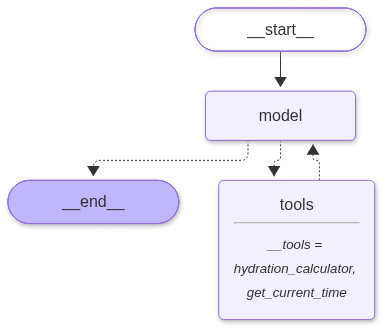

In [12]:
try:
    from IPython.display import Image, display

    display(Image(simple_agent.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"(PNG unavailable: {e})\n")
    print(simple_agent.get_graph().draw_ascii())

<a id="question-2"></a>
#### ❓ Question #2

Looking at the `hydration_calculator` and `get_current_time` tools, why is the **docstring** so important? What would you expect to happen if `hydration_calculator`'s docstring just said `"calculates stuff"`?

> NOTE: Remember what the model actually sees about each tool when it chooses.


The docstring is important because it tells the language model what a tool does, when to use it, and what inputs it expects. When choosing between tools, the model relies on these descriptions to determine which tool is appropriate for a given task. If `hydration_calculator` simply said "calculates stuff," the model would lack the context needed to understand its purpose and might select the wrong tool, fail to use it when appropriate, or provide incorrect arguments. Clear docstrings improve tool selection, execution accuracy, and the reliability of the agent's decisions.

<a id="task-6"></a>
## ✅ Task 6: Agentic RAG — turn retrieval into a tool

<div align="center">
<img src="images/task-6.svg" alt="Agentic RAG: the agent routes the question" width="760">
</div>


This is the core idea of the session. In Session 2, retrieval was a fixed step. Now we make retrieval a tool and let the agent decide when to reach for it.

That's Agentic RAG: the model controls whether and when to retrieve, instead of retrieving on every turn. We reuse the same Health & Wellness Guide from Session 2, but this time store it in Qdrant, a production-style vector database.

### Step 1 — Load & chunk the guide
Same loaders from the `aimakerspace` toolkit you used in Session 2.

In [13]:
from aimakerspace.text_utils import TextFileLoader, CharacterTextSplitter

text_loader = TextFileLoader("data/HealthWellnessGuide.txt")
documents = text_loader.load_documents()

text_splitter = CharacterTextSplitter(chunk_size=500, chunk_overlap=100)
chunks = text_splitter.split_texts(documents)

print(f"Loaded {len(documents)} document(s), split into {len(chunks)} chunks")
print("-" * 50)
print(chunks[0][:300] + "...")

Loaded 1 document(s), split into 41 chunks
--------------------------------------------------
The Personal Wellness Guide
A Comprehensive Resource for Health and Well-being

PART 1: EXERCISE AND MOVEMENT

Chapter 1: Understanding Exercise Basics

Exercise is one of the most important things you can do for your health. Regular physical activity can improve your brain health, help manage weigh...


### Step 2 — Embed & store in Qdrant (on disk)
We embed each chunk with `text-embedding-3-small` and store the vectors in a persistent, on-disk Qdrant collection. Qdrant memory-maps its files to disk by default, so the collection survives a kernel restart. We embed once; every run after that reloads from disk instead of paying to embed again. Pointing the same code at a hosted Qdrant server is a one-line client swap, which is the production path.

> 💡 On-disk Qdrant locks its storage folder to a single client. If a re-run raises *"already accessed by another instance,"* restart the kernel. Your vectors are safe on disk.

In [14]:
from langchain_openai import OpenAIEmbeddings
from langchain_qdrant import QdrantVectorStore
from langchain_core.documents import Document
from qdrant_client import QdrantClient
from qdrant_client.http.models import Distance, VectorParams

embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")
embedding_dim = len(embedding_model.embed_query("test"))

# On-disk Qdrant: vectors persist to memory-mapped files, so they survive a kernel
# restart. Embed once; later runs load from disk instead of paying to re-embed.
QDRANT_PATH = "qdrant_storage"
collection_name = "wellness_knowledge_base"

# The on-disk client locks its folder to one handle — release a previous one on re-run.
_prev_client = globals().get("qdrant_client")
if _prev_client is not None:
    _prev_client.close()
qdrant_client = QdrantClient(path=QDRANT_PATH)
# Hosted/shared instead? Run a Qdrant server, then swap the line above for: QdrantClient(url="http://localhost:6333")

if not qdrant_client.collection_exists(collection_name):
    qdrant_client.create_collection(
        collection_name=collection_name,
        vectors_config=VectorParams(size=embedding_dim, distance=Distance.COSINE),
    )

vector_store = QdrantVectorStore(
    client=qdrant_client,
    collection_name=collection_name,
    embedding=embedding_model,
)

# Only embed when the collection is empty — otherwise reuse what's already on disk.
if qdrant_client.count(collection_name).count == 0:
    vector_store.add_documents([Document(page_content=chunk) for chunk in chunks])
    print(f"Embedded and stored {len(chunks)} chunks in '{collection_name}'")
else:
    print(f"Loaded existing '{collection_name}' from disk — skipped re-embedding")

retriever = vector_store.as_retriever(search_kwargs={"k": 3})
print(f"Retriever ready (dim={embedding_dim}, path='{QDRANT_PATH}/')")

Embedded and stored 41 chunks in 'wellness_knowledge_base'
Retriever ready (dim=1536, path='qdrant_storage/')


### Step 3 — Wrap the retriever as a tool
This is the line that turns RAG *agentic*. The retriever becomes a tool, and its docstring tells the model when to call it.

In [15]:
@tool
def search_wellness_knowledge(query: str) -> str:
    """Search the wellness knowledge base for health, fitness, nutrition, sleep, and mental-wellness info.

    Use this whenever the user asks a wellness question (exercise, diet, sleep, stress, healthy habits).
    Do NOT use it for math, the time, or general trivia.

    Args:
        query: What to look up in the wellness guide.
    """
    results = retriever.invoke(query)
    if not results:
        return "No relevant information found in the wellness knowledge base."
    return "\n\n".join(f"[Source {i}]:\n{doc.page_content}" for i, doc in enumerate(results, 1))


# Quick sanity check: call the tool directly.
print(search_wellness_knowledge.invoke({"query": "how can I improve my sleep?"})[:400] + "...")

[Source 1]:
 memory and learning

Chapter 8: Improving Sleep Quality

Sleep hygiene refers to habits and practices that promote consistent, quality sleep.

Essential sleep hygiene practices:
- Maintain a consistent sleep schedule, even on weekends
- Create a relaxing bedtime routine (reading, gentle stretching, warm bath)
- Keep your bedroom cool, dark, and quiet
- Limit screen exposure 1-2 hours ...


<a id="question-3"></a>
#### ❓ Question #3

How does **Agentic RAG** differ from the traditional retrieve-then-generate pipeline from Session 2? Name one advantage and one potential downside of letting the agent decide when to retrieve.

> NOTE: Consider latency, cost, and what happens when the agent is *wrong* about needing retrieval.


Traditional RAG follows a fixed retrieve-then-generate pipeline, retrieving information before every response regardless of whether it is needed. Agentic RAG gives the language model the ability to decide when to retrieve information by treating retrieval as a tool within an agent loop. One advantage is greater efficiency: the agent can skip unnecessary retrieval, potentially reducing latency and cost. One downside is that the model may incorrectly decide not to retrieve when external evidence is needed, resulting in unsupported or inaccurate answers. Agentic RAG introduces flexibility, but also requires monitoring and evaluation of the agent's retrieval decisions to ensure reliability.

<a id="task-7"></a>
## ✅ Task 7: Add Middleware (logging + a call budget)

<div align="center">
<img src="images/task-7.svg" alt="Middleware: a clipboard beside the model" width="760">
</div>


Middleware is code that runs around the loop. It observes or constrains the agent without you rewriting the loop. Picture a project lead standing next to the model with a clipboard, noting what happened and enforcing limits. It occasionally says "not today."

LangChain gives you hooks at each stage of the loop. We'll use two:
- **`before_model` / `after_model`**: log a compact view of each turn so the trace is visible.
- **`ModelCallLimitMiddleware`**: a built-in budget that stops a runaway agent after N model calls.

In [16]:
from langchain.agents.middleware import before_model, after_model, ModelCallLimitMiddleware

model_call_count = 0


@before_model
def log_before_model(state, runtime):
    """Runs before each model call."""
    global model_call_count
    model_call_count += 1
    print(f"[LOG] model call #{model_call_count} — messages in state: {len(state.get('messages', []))}")
    return None  # None = continue unchanged


@after_model
def log_after_model(state, runtime):
    """Runs after each model call."""
    messages = state.get("messages", [])
    last = messages[-1] if messages else None
    requested_tools = bool(getattr(last, "tool_calls", None))
    print(f"[LOG] after model — requested a tool call: {requested_tools}")
    return None


# Built-in budget: cap model calls so the agent can't loop forever.
call_limiter = ModelCallLimitMiddleware(thread_limit=10, run_limit=5, exit_behavior="end")

print("Middleware ready: log_before_model, log_after_model, call_limiter")

Middleware ready: log_before_model, log_after_model, call_limiter


### Assemble the finished agent
Now we combine everything: the RAG tool, the warm-up tools, a wellness system prompt with guardrails, and the middleware stack. This is the exact block from the top of the notebook.

In [17]:
WELLNESS_SYSTEM_PROMPT = """You are a supportive wellness assistant with a health & wellness knowledge base.

Your job:
1. For questions about health, fitness, nutrition, sleep, or stress, ALWAYS search the knowledge base first.
2. Answer using the retrieved context; if it isn't there, say so honestly rather than guessing.
3. For a water-intake estimate or the time, use the appropriate tool. For anything else, just answer.
4. Be encouraging, and remind users to consult a healthcare professional for medical concerns.
"""

wellness_agent = create_agent(
    model=AGENT_MODEL,
    tools=[search_wellness_knowledge, hydration_calculator, get_current_time],
    system_prompt=WELLNESS_SYSTEM_PROMPT,
    middleware=[log_before_model, log_after_model, call_limiter],
)

print("Wellness Agentic RAG agent created with middleware!")

Wellness Agentic RAG agent created with middleware!


### Watch it decide
Two runs tell the story. The first is a wellness question, so the agent should call `search_wellness_knowledge`. The second is a hydration calculation, so it should not touch RAG. Read the `[LOG]` lines to confirm.

In [18]:
model_call_count = 0
print("=== WELLNESS QUESTION (expect a RAG search) ===")
r1 = wellness_agent.invoke(
    {"messages": [{"role": "user", "content": "What are some tips for better sleep?"}]}
)
show_answer(r1["messages"][-1].content)

=== WELLNESS QUESTION (expect a RAG search) ===
[LOG] model call #1 — messages in state: 1
[LOG] after model — requested a tool call: True
[LOG] model call #2 — messages in state: 3
[LOG] after model — requested a tool call: False


**Final answer**

Here are practical ways to improve sleep:

- **Keep a consistent schedule:** Go to bed and wake up around the same time every day, including weekends.
- **Build a wind-down routine:** Try reading, gentle stretching, a warm bath, or progressive muscle relaxation.
- **Optimize your bedroom:** Keep it **cool (about 65–68°F / 18–20°C), dark, and quiet**. Consider blackout curtains, a sleep mask, or earplugs.
- **Reduce evening screens:** Avoid phones, computers, and TV for **1–2 hours before bed**.
- **Limit stimulants:** Avoid caffeine after about **2 p.m.**
- **Be active regularly:** Exercise can help, but avoid strenuous workouts too close to bedtime.
- **Limit alcohol near bedtime:** It can make sleep more fragmented even if it initially makes you drowsy.
- **Aim for adequate sleep:** Most adults generally need **7–9 hours**.

If trouble falling or staying asleep happens at least three nights per week for three months or longer, consider speaking with a healthcare professional. **Cognitive behavioral therapy for insomnia (CBT-I)** is an effective treatment for chronic insomnia.

In [19]:
model_call_count = 0
print("=== HYDRATION QUESTION (expect NO RAG search) ===")
r2 = wellness_agent.invoke(
    {"messages": [{"role": "user", "content": "How much water should I drink at 72 kg?"}]}
)
show_answer(r2["messages"][-1].content)

=== HYDRATION QUESTION (expect NO RAG search) ===
[LOG] model call #1 — messages in state: 1
[LOG] after model — requested a tool call: True
[LOG] model call #2 — messages in state: 4
[LOG] after model — requested a tool call: False


**Final answer**

At **72 kg**, aim for about **85 oz (2.5 liters), or roughly 10–11 glasses of water daily** on a typical day with no planned exercise.

You may need more with exercise, hot weather, illness, pregnancy, or breastfeeding. A practical hydration sign is **pale-yellow urine**; dark yellow urine can suggest dehydration. If you have kidney, heart, or fluid-balance concerns, consult a healthcare professional about your appropriate intake.

Confirm it with the reasoning trace: which tools did each run actually use?

In [20]:
print("Wellness run used:")
print(extract_reasoning(r1)["reasoning"] or "  [no tools]")
print("\nHydration run used:")
print(extract_reasoning(r2)["reasoning"] or "  [no tools]")

Wellness run used:
Action: search_wellness_knowledge  Input: {'query': 'evidence-based tips for better sleep, sleep hygiene, insomnia warning signs'}
Observation from search_wellness_knowledge: [Source 1]:
 memory and learning

Chapter 8: Improving Sleep Quality

Sleep hygiene refers to habits and practices that promote consistent, quality sleep.

Essential sleep hygiene practices:
- Maintain a consistent sleep schedule, even on weekends
- Create a relaxing bedtime routine (reading, gentle

Hydration run used:
Action: hydration_calculator  Input: {'weight_kg': 72, 'activity_minutes': 0}
Action: search_wellness_knowledge  Input: {'query': 'daily water intake guidance, hydration needs, and factors that increase water requirements'}
Observation from hydration_calculator: About 85 oz (~10.7 glasses of water) today. The guide's baseline is 8 glasses / 64 oz, scaled for your body size and activity.
Observation from search_wellness_knowledge: [Source 1]:
on is to drink 8 glasses (64 ounces) o

<a id="question-4"></a>
#### ❓ Question #4

Describe a real-world scenario where middleware is *essential* for a production agent, not just nice to have. What would go wrong without it?

> NOTE: Think about cost blowups, safety, auditing, and the loop that never ends.


Middleware is essential in a production agent that supports financial services, such as an AI assistant evaluating supplier contracts or procurement decisions. Without middleware, the agent could repeatedly call expensive APIs, enter an uncontrolled loop, expose sensitive financial information, or make recommendations without sufficient oversight. Middleware provides safeguards such as tool-call limits, cost controls, access restrictions, logging, and audit trails. For example, a call-budget middleware could stop an agent that repeatedly searches the same documents without reaching a conclusion, preventing excessive costs and resource consumption. In production, middleware helps ensure that agent behavior remains bounded, observable, secure, and accountable rather than relying solely on the model to regulate itself.

> 🧑‍🤝‍🧑 **Breakout Room #2.** Now that the agent retrieves from the guide (Task 6) and runs under logging + a call budget (Task 7), compare runs as a group: which request made it call `search_wellness_knowledge`, which did it answer directly, and what did the middleware make visible or stop? Then look ahead to [**Technical Challenge 2**](../00_Technical_Challenges/Week%202/README.md): which augmentation (a new tool, custom middleware, citations, a tool-call budget, or human-in-the-loop) would you reach for first, and why?

<a id="recap"></a>
## 🏗️ End of the Sesh (recap)

Here's the finished agent again, the same block we opened with. After building every piece, it should read like plain English:

```python
from langchain.agents import create_agent

wellness_agent = create_agent(
    model=AGENT_MODEL,                      # the LLM that does the reasoning
    tools=[
        search_wellness_knowledge,          # Agentic RAG: retrieve only when needed
        hydration_calculator,
        get_current_time,
    ],
    system_prompt=WELLNESS_SYSTEM_PROMPT,   # the job description + guardrails
    middleware=[
        log_before_model,                   # observe each step
        log_after_model,
        call_limiter,                       # enforce a model-call budget
    ],
)

response = wellness_agent.invoke(
    {"messages": [{"role": "user", "content": "What are some tips for better sleep?"}]}
)
print(response["messages"][-1].content)
```

A model, a toolbox, a job description, and a harness around the loop. That's the whole session.

<a id="business-case"></a>
## 💼 Business Case Study

Marcus is a solutions engineer at a health-tech startup. His team ships a chatbot that answers members' wellness questions from a curated guide. The first version was exactly the Session 2 pipeline: every message triggered a retrieval, even "thanks!" and "what's 20% of my 2,000-calorie goal?". So the bot quoted sleep-hygiene tips at people doing arithmetic, and the embedding bill grew with every message.

Then leadership asked the uncomfortable, useful question: "How do we know it won't call the wrong tool, loop forever, or answer outside its lane?"

Marcus rebuilds it as an agent harness. Retrieval becomes a tool the model calls only for wellness questions, a hydration calculator does the water math, and middleware logs each step and caps model calls so a confused run can't rack up a bill. Now when compliance asks "why did it say that?", Marcus hands them the trace: which tools fired, with what inputs, and what came back. The demo is no longer a black box he has to trust. It's something he can defend.

That's the jump this session makes. You go from a pipeline that always does the same thing to an agent whose behavior you can inspect and bound.

<a id="production"></a>
## 🏭 What We Built vs. What's in Production

Our wellness agent is deliberately small so every part stays visible. A production agent keeps the same shape but hardens each stage:

| Stage | 🧪 What we built (toy) | 🏭 What's in production |
|---|---|---|
| **Model** | One model string, fixed | Model routing by cost/latency, fallbacks, versioned prompts |
| **Tools** | Three local Python functions | Tool catalog over live systems with auth, rate limits, audit logs, and regression tests |
| **Vector store** | On-disk Qdrant (embedded), persists across restarts | Hosted/clustered Qdrant with replication, snapshots, and quantization |
| **Retrieval** | Top-`k` dense search, `k=3` | Metadata filtering, hybrid (dense + BM25), reranking, citations |
| **Agentic decision** | Model decides from docstrings | Evaluated routing, few-shot tool examples, guardrails on tool choice |
| **Middleware** | `print` logging + a call limit | Structured tracing (LangSmith), budgets on cost/latency/tool calls, retries, PII filters |
| **Human oversight** | None | Human-in-the-loop approval before risky tool calls |
| **Quality** | Eyeball the trace ("vibe check") | Offline eval sets, trace assertions in CI, online feedback loops |
| **Serving & ops** | Runs cell-by-cell in a notebook | API service with monitoring, caching, rate limits, and alerting |

<a id="conclusion"></a>
## 👋 Conclusion

Nice work. You turned a fixed RAG pipeline into an agent and watched it decide for itself when to retrieve. You:

- built a baseline agent with `create_agent` (model, tools, system prompt),
- made retrieval a tool backed by a Qdrant vector store, which is the heart of Agentic RAG,
- inspected the loop by pulling a reasoning trace, streaming updates, and rendering the graph,
- wrapped the loop in middleware to log every step and cap model calls.

That's the agent loop: decide, maybe act, then answer, with a harness around it so you can see the behavior and keep it in bounds.

### Your turn this week — build 🏗️ ship 🚢 share 🚀

Head to the [session README](./README.md) for the full technical challenge:

- **Build:** run the notebook and answer Questions #1–#4.
- **Ship:** take the agent out of the notebook in [Technical Challenge 2](../00_Technical_Challenges/Week%202/README.md) — stand it up as a FastAPI agentic-RAG service, fill in the stubs, and add one augmentation (a new tool, custom middleware, citations, a tool-call budget, or human-in-the-loop approval), then compare its trace to the baseline.
- **Share:** record a Loom walkthrough and post three lessons learned, tagging @AIMakerspace.

> ⏭️ **Next up: Session 4, Agentic RAG From Scratch.**

<a id="docs"></a>
## 📖 Official Documentation

Everything this notebook builds on, straight from the maintainers:

**LangChain 1.0**
- [Agents & `create_agent`](https://docs.langchain.com/oss/python/langchain/agents) — the agent loop API
- [Tools](https://docs.langchain.com/oss/python/langchain/tools) — the `@tool` decorator and tool schemas
- [Middleware](https://docs.langchain.com/oss/python/langchain/middleware) — `before_model`/`after_model`, `ModelCallLimitMiddleware`, `ToolCallLimitMiddleware`
- [Streaming](https://docs.langchain.com/oss/python/langchain/streaming) — `stream_mode="updates"` and friends

**LangGraph & LangSmith**
- [LangGraph](https://docs.langchain.com/oss/python/langgraph/overview) — the graph `create_agent` compiles under the hood
- [LangSmith tracing](https://docs.smith.langchain.com/) — visualize and assert on agent traces

**Foundational paper**
- [ReAct: Synergizing Reasoning and Acting in Language Models](https://arxiv.org/abs/2210.03629) — Yao et al., 2022 — the reason → act → observe loop `create_agent` wires for you

**Vector store & embeddings**
- [Qdrant](https://qdrant.tech/documentation/) · [`langchain-qdrant`](https://docs.langchain.com/oss/python/integrations/vectorstores/qdrant)
- [OpenAI Embeddings](https://platform.openai.com/docs/guides/embeddings) — `text-embedding-3-small`

**Python stack**
- [python-dotenv](https://github.com/theskumar/python-dotenv) · [nest_asyncio](https://github.com/erdewit/nest_asyncio) · [uv](https://docs.astral.sh/uv/)